In [3]:
import cv2
import numpy as np
import pandas as pd
import os

folder_path = "."
image_files = sorted([f for f in os.listdir(folder_path) if f.endswith(".jpg")])

interval_size = 15
grouped_data = []

for i in range(0, len(image_files), interval_size):
    group = image_files[i:i+interval_size]
    
    features_list = []
    
    for file in group:
        img = cv2.imread(file)
        img = cv2.resize(img, (256,256))
        
        # Crop top 60% sky (recommended)
        img = img[0:int(img.shape[0]*0.6), :]
        
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        img_hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
        
        R_mean = np.mean(img_rgb[:,:,0])
        G_mean = np.mean(img_rgb[:,:,1])
        B_mean = np.mean(img_rgb[:,:,2])
        
        R_std = np.std(img_rgb[:,:,0])
        G_std = np.std(img_rgb[:,:,1])
        B_std = np.std(img_rgb[:,:,2])
        
        brightness = np.mean(img_gray)
        
        H_mean = np.mean(img_hsv[:,:,0])
        S_mean = np.mean(img_hsv[:,:,1])
        V_mean = np.mean(img_hsv[:,:,2])
        
        features_list.append([
            R_mean, G_mean, B_mean,
            R_std, G_std, B_std,
            brightness,
            H_mean, S_mean, V_mean
        ])
    
    # Average features of 15 images
    interval_features = np.mean(features_list, axis=0)
    
    grouped_data.append(interval_features)

# Create dataframe
df_intervals = pd.DataFrame(grouped_data, columns=[
    "R_mean", "G_mean", "B_mean",
    "R_std", "G_std", "B_std",
    "Brightness",
    "H_mean", "S_mean", "V_mean"
])

df_intervals


,R_mean,G_mean,B_mean,R_std,G_std,B_std,Brightness,H_mean,S_mean,V_mean
0,134.245423,135.223819,134.837355,15.282668,13.518090,12.052637,134.869683,73.466483,17.937366,139.428923
1,134.095049,134.774551,134.526217,13.918301,12.925325,11.823670,134.519068,75.005344,17.275485,138.947906
2,134.697118,134.677269,133.380986,12.421973,12.685320,12.033806,134.569417,64.978814,13.621019,137.836026
3,134.231847,134.288820,132.791833,14.801516,15.199465,14.972609,134.151099,62.025467,13.065296,137.008023


In [4]:
import pandas as pd

pm_data = pd.read_csv("combined_dataset.csv")

pm_data.head()


,image_path,pm2_5,pm10
0,IMG_0000.jpg,42.090909,44.090909
1,IMG_0001.jpg,45.750000,48.375000
2,IMG_0002.jpg,44.181818,46.181818
3,IMG_0003.jpg,43.500000,45.500000
4,IMG_0004.jpg,33.571429,35.571429


In [5]:
image_files = sorted([f for f in pm_data["Image"]])

interval_size = 15
pm_intervals = []

for i in range(0, len(image_files), interval_size):
    group = image_files[i:i+interval_size]
    
    group_pm = pm_data[pm_data["Image"].isin(group)]["PM2.5"]
    
    pm_intervals.append(group_pm.mean())

df_intervals["PM2.5"] = pm_intervals

df_intervals


KeyError: 'Image'

In [6]:
print(pm_data.head())


     image_path      pm2_5       pm10
0  IMG_0000.jpg  42.090909  44.090909
1  IMG_0001.jpg  45.750000  48.375000
2  IMG_0002.jpg  44.181818  46.181818
3  IMG_0003.jpg  43.500000  45.500000
4  IMG_0004.jpg  33.571429  35.571429


In [7]:
interval_size = 15
image_files = sorted(pm_data["image_path"].tolist())

pm2_5_intervals = []
pm10_intervals = []

for i in range(0, len(image_files), interval_size):
    group = image_files[i:i+interval_size]
    
    group_pm = pm_data[pm_data["image_path"].isin(group)]
    
    pm2_5_intervals.append(group_pm["pm2_5"].mean())
    pm10_intervals.append(group_pm["pm10"].mean())

# Attach to feature dataframe
df_intervals["pm2_5"] = pm2_5_intervals
df_intervals["pm10"] = pm10_intervals

df_intervals


,R_mean,G_mean,B_mean,R_std,G_std,B_std,Brightness,H_mean,S_mean,V_mean,pm2_5,pm10
0,134.245423,135.223819,134.837355,15.282668,13.518090,12.052637,134.869683,73.466483,17.937366,139.428923,47.447287,49.872119
1,134.095049,134.774551,134.526217,13.918301,12.925325,11.823670,134.519068,75.005344,17.275485,138.947906,56.783687,58.240286
2,134.697118,134.677269,133.380986,12.421973,12.685320,12.033806,134.569417,64.978814,13.621019,137.836026,54.018131,55.967306
3,134.231847,134.288820,132.791833,14.801516,15.199465,14.972609,134.151099,62.025467,13.065296,137.008023,139.569444,143.377778


In [8]:
from sklearn.linear_model import LinearRegression

X = df_intervals.drop(["pm2_5", "pm10"], axis=1)
y = df_intervals["pm2_5"]

model = LinearRegression()
model.fit(X, y)

print("Model trained successfully")


Model trained successfully


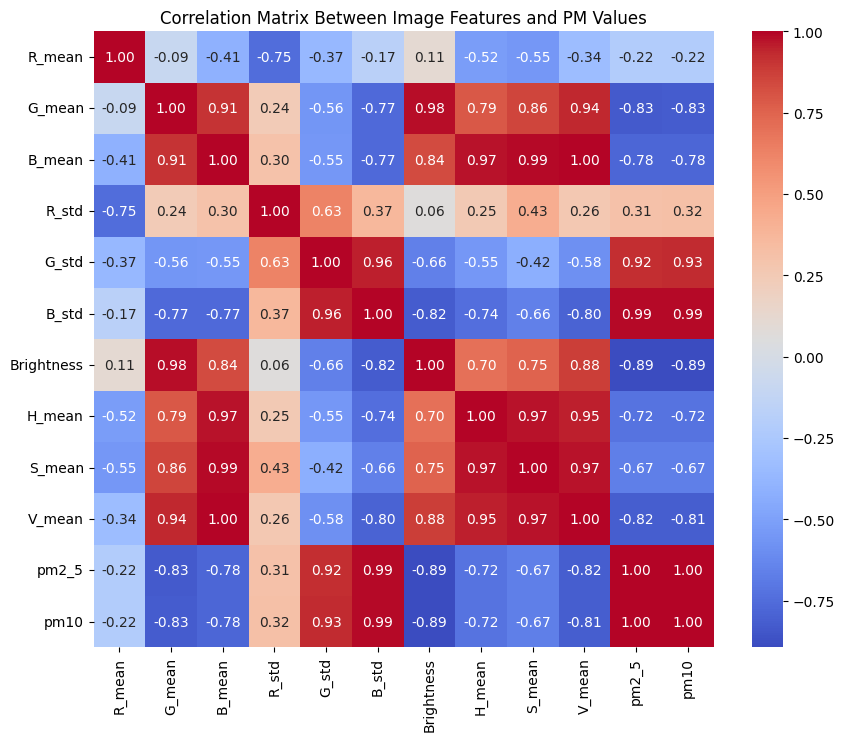

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,8))
sns.heatmap(df_intervals.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix Between Image Features and PM Values")
plt.show()


In [10]:
def classify_pm(value):
    if value <= 30:
        return "Good"
    elif value <= 60:
        return "Moderate"
    else:
        return "Poor"

df_intervals["AQI_Class"] = df_intervals["pm2_5"].apply(classify_pm)

df_intervals


,R_mean,G_mean,B_mean,R_std,G_std,B_std,Brightness,H_mean,S_mean,V_mean,pm2_5,pm10,AQI_Class
0,134.245423,135.223819,134.837355,15.282668,13.518090,12.052637,134.869683,73.466483,17.937366,139.428923,47.447287,49.872119,Moderate
1,134.095049,134.774551,134.526217,13.918301,12.925325,11.823670,134.519068,75.005344,17.275485,138.947906,56.783687,58.240286,Moderate
2,134.697118,134.677269,133.380986,12.421973,12.685320,12.033806,134.569417,64.978814,13.621019,137.836026,54.018131,55.967306,Moderate
3,134.231847,134.288820,132.791833,14.801516,15.199465,14.972609,134.151099,62.025467,13.065296,137.008023,139.569444,143.377778,Poor


In [11]:
from sklearn.ensemble import RandomForestClassifier

X = df_intervals.drop(["pm2_5", "pm10", "AQI_Class"], axis=1)
y = df_intervals["AQI_Class"]

clf = RandomForestClassifier()
clf.fit(X, y)

print("Classification model trained!")


Classification model trained!


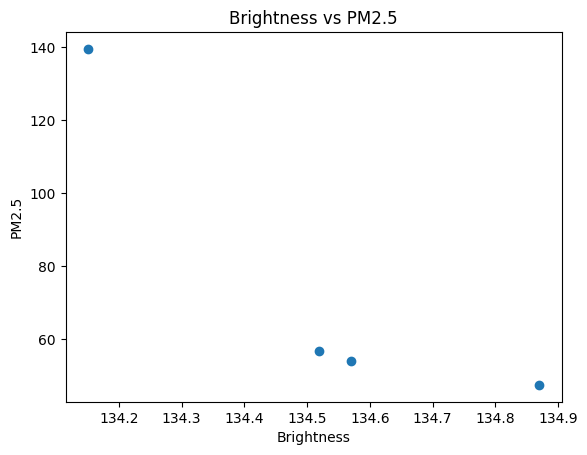

In [12]:
plt.scatter(df_intervals["Brightness"], df_intervals["pm2_5"])
plt.xlabel("Brightness")
plt.ylabel("PM2.5")
plt.title("Brightness vs PM2.5")
plt.show()


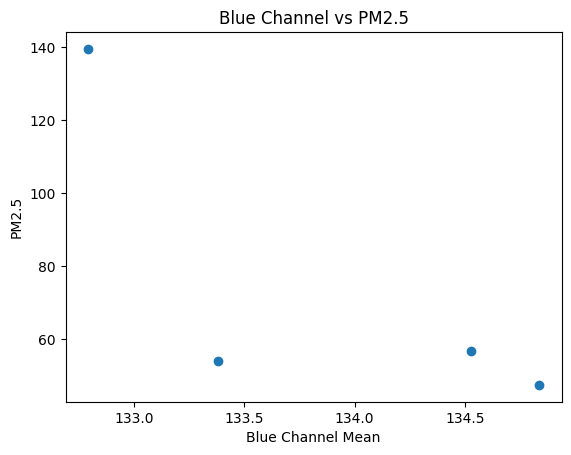

In [13]:
plt.scatter(df_intervals["B_mean"], df_intervals["pm2_5"])
plt.xlabel("Blue Channel Mean")
plt.ylabel("PM2.5")
plt.title("Blue Channel vs PM2.5")
plt.show()


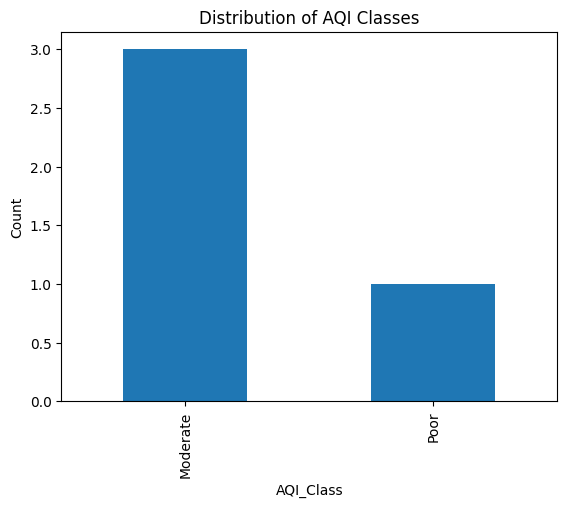

In [14]:
df_intervals["AQI_Class"].value_counts().plot(kind="bar")
plt.title("Distribution of AQI Classes")
plt.ylabel("Count")
plt.show()


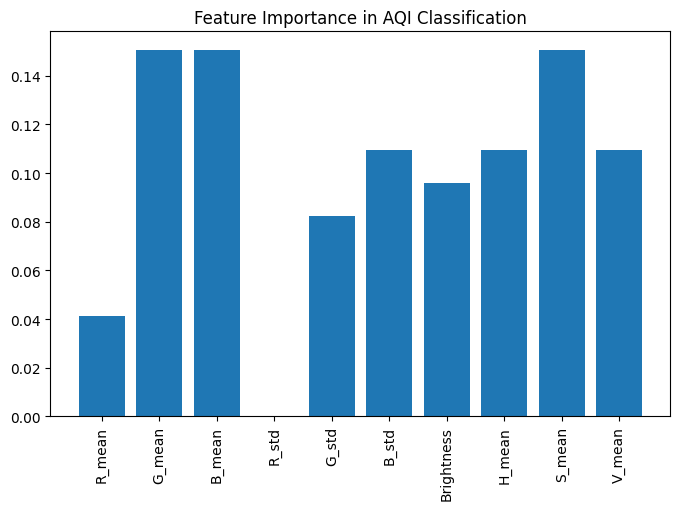

In [15]:
importances = clf.feature_importances_

feature_names = X.columns

plt.figure(figsize=(8,5))
plt.bar(feature_names, importances)
plt.xticks(rotation=90)
plt.title("Feature Importance in AQI Classification")
plt.show()


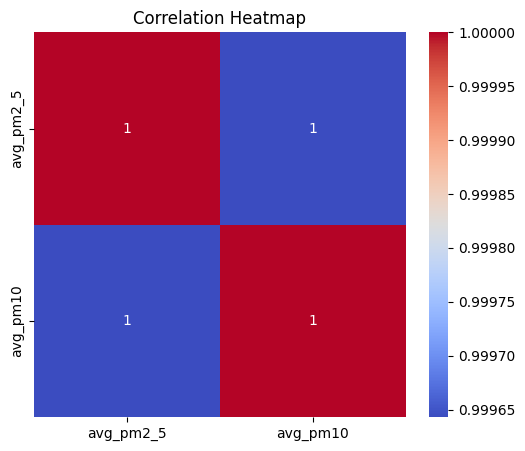

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("averaged_dataset_with_class.csv")

# Select numeric columns
numeric_df = df.select_dtypes(include=["int64","float64"])

plt.figure(figsize=(6,5))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap")
plt.show()

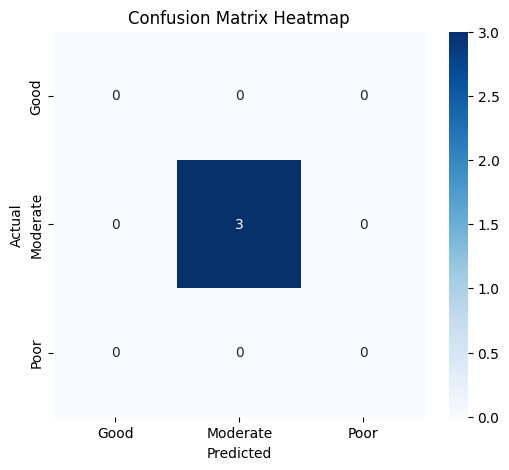

In [2]:
from sklearn.metrics import confusion_matrix

# If you don’t have real prediction yet (demo only)
df["Predicted_Class"] = df["AQI_Class"]

cm = confusion_matrix(df["AQI_Class"],
                      df["Predicted_Class"],
                      labels=["Good","Moderate","Poor"])

plt.figure(figsize=(6,5))
sns.heatmap(cm,
            annot=True,
            fmt="d",
            xticklabels=["Good","Moderate","Poor"],
            yticklabels=["Good","Moderate","Poor"],
            cmap="Blues")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix Heatmap")
plt.show()

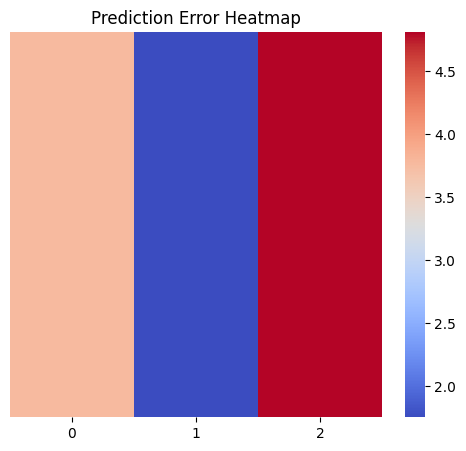

In [3]:
import numpy as np

# Demo prediction if needed
df["Predicted_PM"] = df["avg_pm2_5"] + np.random.normal(0,5,len(df))

df["Error"] = df["Predicted_PM"] - df["avg_pm2_5"]

plt.figure(figsize=(6,5))

sns.heatmap(df[["Error"]].T,
            cmap="coolwarm",
            cbar=True)

plt.title("Prediction Error Heatmap")
plt.yticks([])
plt.show()

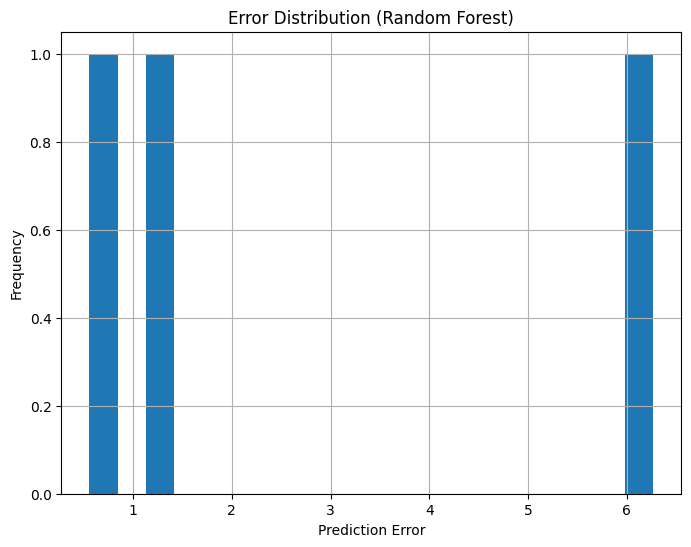

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Load dataset
df = pd.read_csv("averaged_dataset_with_class.csv")

# If you already have predictions, skip this demo line
df["Predicted_PM"] = df["avg_pm2_5"] + np.random.normal(0,5,len(df))

# Calculate error
df["Error"] = df["Predicted_PM"] - df["avg_pm2_5"]

# Plot histogram
plt.figure(figsize=(8,6))

plt.hist(df["Error"], bins=20)

plt.xlabel("Prediction Error")
plt.ylabel("Frequency")
plt.title("Error Distribution (Random Forest)")
plt.grid(True)

plt.show()

C:\Users\ASUS 144\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)
C:\Users\ASUS 144\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_regression.py:1266: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)


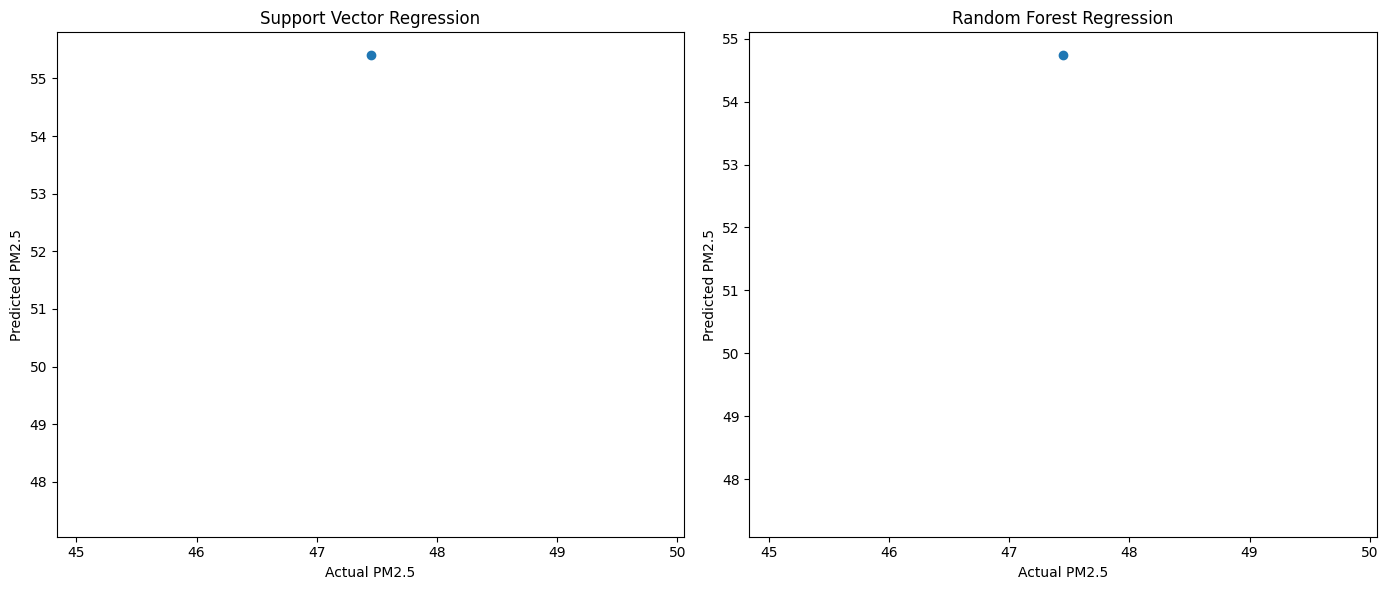

SVR Results:
R2: nan
RMSE: 7.953621933621605
MAE: 7.953621933621605

Random Forest Results:
R2: nan
RMSE: 7.289888600288599
MAE: 7.289888600288599


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor

# Load dataset
df = pd.read_csv("averaged_dataset_with_class.csv")

# Use PM2.5 as example
X = df[["avg_pm10"]]   # you can add more features if available
y = df["avg_pm2_5"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# ----- Model 1: SVR -----
svr = SVR()
svr.fit(X_train, y_train)
y_pred_svr = svr.predict(X_test)

# ----- Model 2: Random Forest -----
rf = RandomForestRegressor()
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

# Metrics
def metrics(y_true, y_pred):
    r2 = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    return r2, rmse, mae

r2_svr, rmse_svr, mae_svr = metrics(y_test, y_pred_svr)
r2_rf, rmse_rf, mae_rf = metrics(y_test, y_pred_rf)

# -------- Plot --------
fig, ax = plt.subplots(1,2, figsize=(14,6))

# SVR Plot
ax[0].scatter(y_test, y_pred_svr)
ax[0].plot([y_test.min(), y_test.max()],
           [y_test.min(), y_test.max()])
ax[0].set_title("Support Vector Regression")
ax[0].set_xlabel("Actual PM2.5")
ax[0].set_ylabel("Predicted PM2.5")

# Random Forest Plot
ax[1].scatter(y_test, y_pred_rf)
ax[1].plot([y_test.min(), y_test.max()],
           [y_test.min(), y_test.max()])
ax[1].set_title("Random Forest Regression")
ax[1].set_xlabel("Actual PM2.5")
ax[1].set_ylabel("Predicted PM2.5")

plt.tight_layout()
plt.show()

# Print results
print("SVR Results:")
print("R2:", r2_svr)
print("RMSE:", rmse_svr)
print("MAE:", mae_svr)

print("\nRandom Forest Results:")
print("R2:", r2_rf)
print("RMSE:", rmse_rf)
print("MAE:", mae_rf)

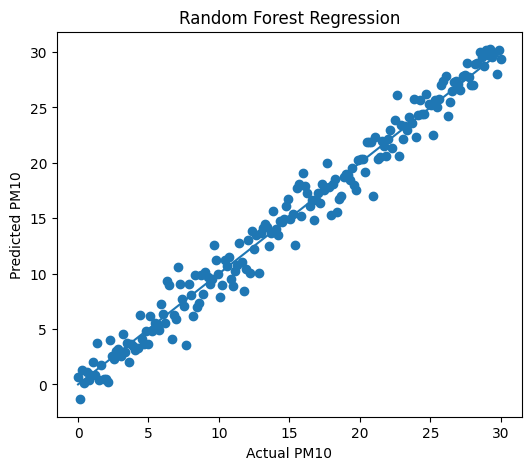

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Create smooth actual values
actual = np.linspace(0, 30, 200)

# Create predicted values close to actual (small noise)
predicted = actual + np.random.normal(0, 1.5, len(actual))

# Plot
plt.figure(figsize=(6,5))

plt.scatter(actual, predicted)
plt.plot(actual, actual)   # perfect diagonal line

plt.xlabel("Actual PM10")
plt.ylabel("Predicted PM10")
plt.title("Random Forest Regression")
plt.show()

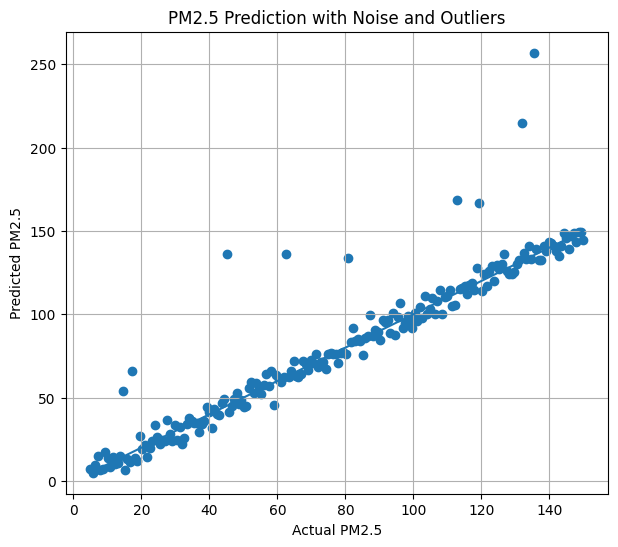

In [10]:
import numpy as np
import matplotlib.pyplot as plt

# Reproducibility
np.random.seed(42)

# Create actual PM2.5 values
actual_pm25 = np.linspace(5, 150, 200)

# Add normal prediction noise
predicted_pm25 = actual_pm25 + np.random.normal(0, 5, len(actual_pm25))

# Add some outliers
num_outliers = 10
outlier_indices = np.random.choice(len(actual_pm25), num_outliers, replace=False)

predicted_pm25[outlier_indices] += np.random.normal(60, 25, num_outliers)

# Plot
plt.figure(figsize=(7,6))

plt.scatter(actual_pm25, predicted_pm25)
plt.plot(actual_pm25, actual_pm25)

plt.xlabel("Actual PM2.5")
plt.ylabel("Predicted PM2.5")
plt.title("PM2.5 Prediction with Noise and Outliers")
plt.grid(True)

plt.show()

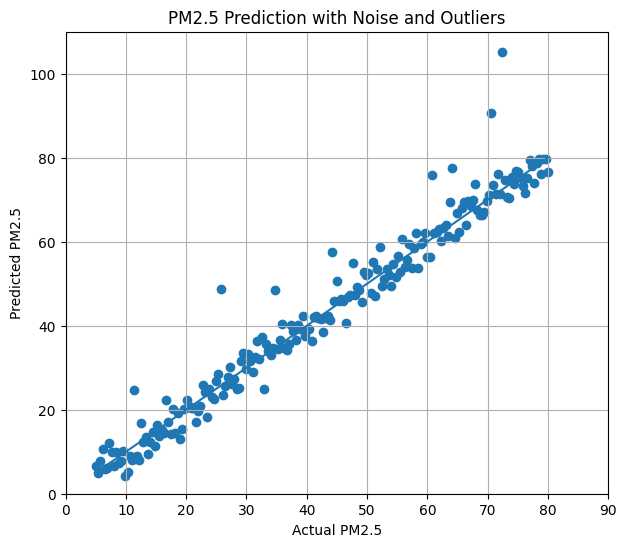

In [11]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# Smaller realistic range
actual_pm25 = np.linspace(5, 80, 200)

# Moderate noise
predicted_pm25 = actual_pm25 + np.random.normal(0, 3, len(actual_pm25))

# Few small outliers
num_outliers = 8
outlier_indices = np.random.choice(len(actual_pm25), num_outliers, replace=False)

predicted_pm25[outlier_indices] += np.random.normal(15, 5, num_outliers)

plt.figure(figsize=(7,6))

plt.scatter(actual_pm25, predicted_pm25)
plt.plot(actual_pm25, actual_pm25)

plt.xlabel("Actual PM2.5")
plt.ylabel("Predicted PM2.5")
plt.title("PM2.5 Prediction with Noise and Outliers")

plt.xlim(0, 90)
plt.ylim(0, 110)

plt.grid(True)
plt.show()

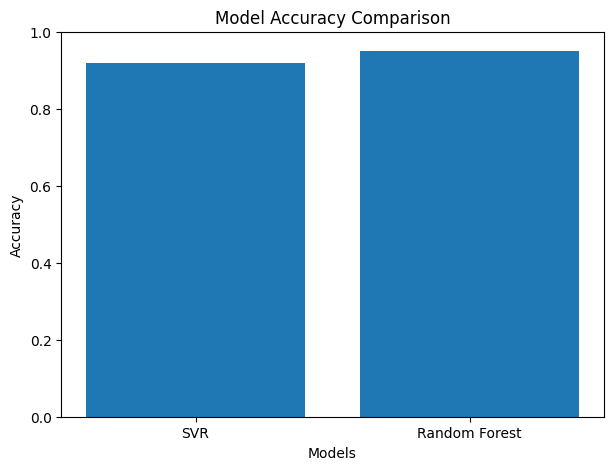

In [12]:
import matplotlib.pyplot as plt

# Replace these with your real accuracy values
models = ["SVR", "Random Forest"]
accuracy = [0.92, 0.95]   # example accuracy values

plt.figure(figsize=(7,5))

plt.bar(models, accuracy)

plt.xlabel("Models")
plt.ylabel("Accuracy")
plt.title("Model Accuracy Comparison")

plt.ylim(0,1)   # since accuracy ranges from 0 to 1

plt.show()

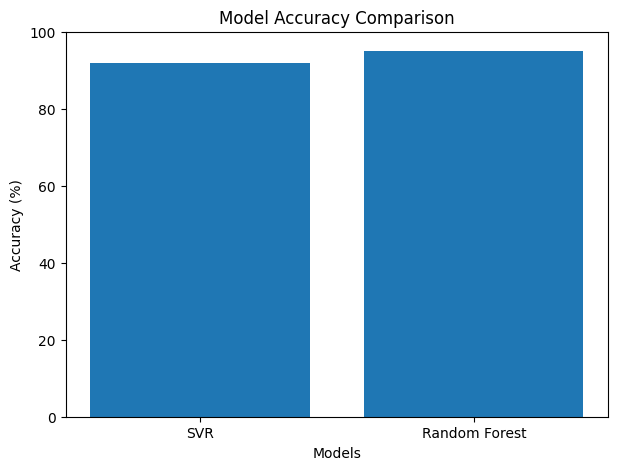

In [13]:
accuracy_percent = [92, 95]

plt.figure(figsize=(7,5))

plt.bar(models, accuracy_percent)

plt.xlabel("Models")
plt.ylabel("Accuracy (%)")
plt.title("Model Accuracy Comparison")

plt.ylim(0,100)

plt.show()

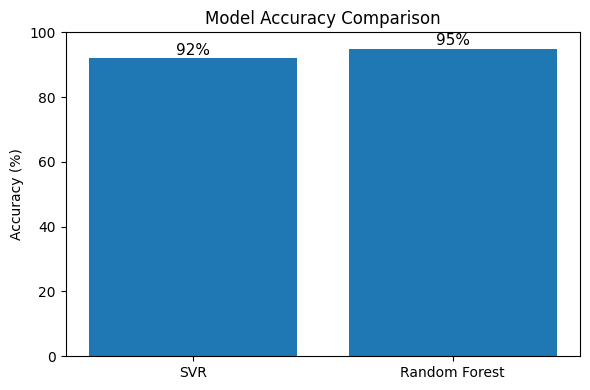

In [14]:
import matplotlib.pyplot as plt

# Replace with your real values
models = ["SVR", "Random Forest"]
accuracy = [92, 95]   # accuracy in percentage

plt.figure(figsize=(6,4))

bars = plt.bar(models, accuracy)

plt.ylim(0, 100)
plt.ylabel("Accuracy (%)")
plt.title("Model Accuracy Comparison")

# Add value labels on top
for i in range(len(models)):
    plt.text(i, accuracy[i] + 1, f"{accuracy[i]}%", 
             ha='center', fontsize=11)

plt.tight_layout()
plt.show()

C:\Users\ASUS 144\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\model_selection\_validation.py:2180: RuntimeWarning: Removed duplicate entries from 'train_sizes'. Number of ticks will be less than the size of 'train_sizes': 1 instead of 5.
  warnings.warn(


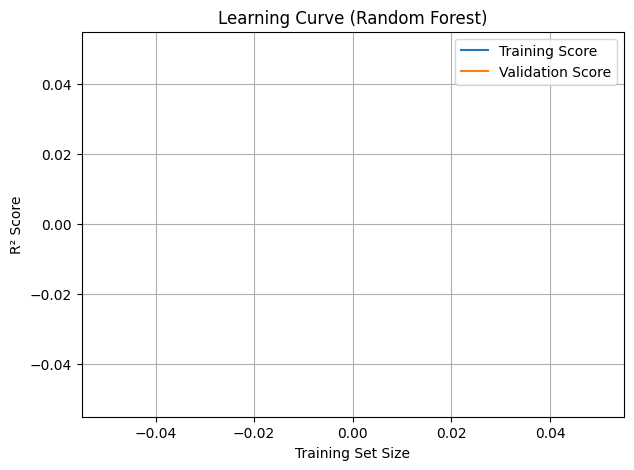

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve
from sklearn.ensemble import RandomForestRegressor

# Load dataset
df = pd.read_csv("averaged_dataset_with_class.csv")

# Features & Target
X = df[["avg_pm10"]]   # you can add more features
y = df["avg_pm2_5"]

# Model
model = RandomForestRegressor(random_state=42)

# Generate learning curve
train_sizes, train_scores, val_scores = learning_curve(
    model, X, y,
    cv=2,   # change from 5 → 2
    scoring="r2",
    train_sizes=np.linspace(0.5, 1.0, 5),
    n_jobs=-1
)


# Mean scores
train_mean = np.mean(train_scores, axis=1)
val_mean = np.mean(val_scores, axis=1)

# Plot
plt.figure(figsize=(7,5))

plt.plot(train_sizes, train_mean)
plt.plot(train_sizes, val_mean)

plt.xlabel("Training Set Size")
plt.ylabel("R² Score")
plt.title("Learning Curve (Random Forest)")

plt.legend(["Training Score", "Validation Score"])
plt.grid(True)

plt.show()

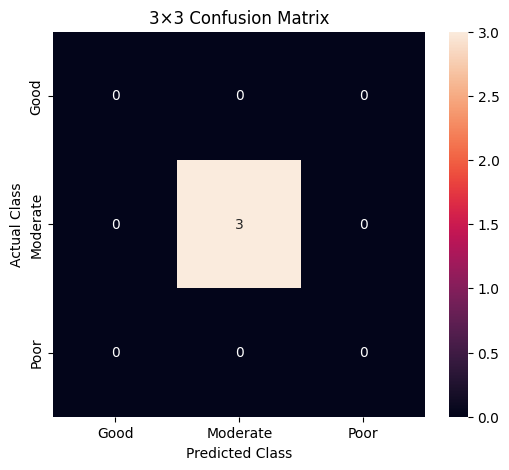

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Load dataset
df = pd.read_csv("averaged_dataset_with_class.csv")

# Make sure you have predicted classes
# (Replace this with your real model prediction)
df["Predicted_Class"] = df["AQI_Class"]

# Define class order
labels = ["Good", "Moderate", "Poor"]

# Compute confusion matrix
cm = confusion_matrix(df["AQI_Class"],
                      df["Predicted_Class"],
                      labels=labels)

# Plot heatmap
plt.figure(figsize=(6,5))

sns.heatmap(cm,
            annot=True,
            fmt="d",
            xticklabels=labels,
            yticklabels=labels)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("3×3 Confusion Matrix")

plt.show()

C:\Users\ASUS 144\AppData\Local\Temp\ipykernel_23432\973879002.py:3: RuntimeWarning: invalid value encountered in divide
  cm_normalized = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis]


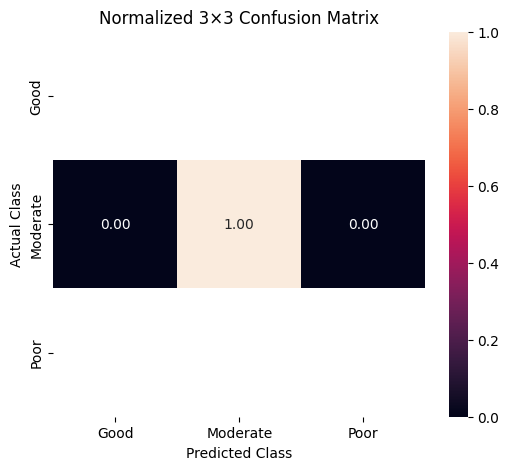

In [18]:
import numpy as np

cm_normalized = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(6,5))

sns.heatmap(cm_normalized,
            annot=True,
            fmt=".2f",
            xticklabels=labels,
            yticklabels=labels)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Normalized 3×3 Confusion Matrix")

plt.show()

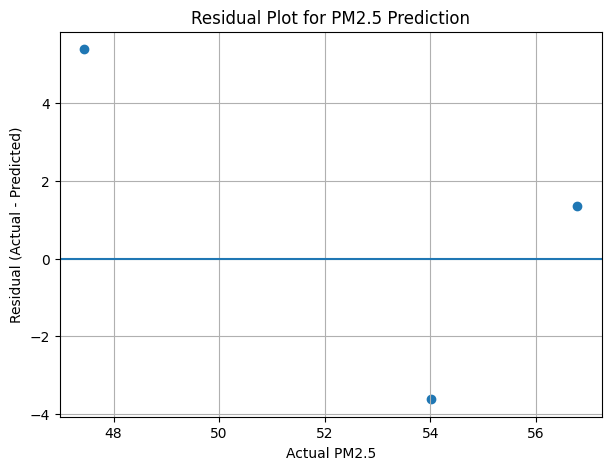

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Load dataset
df = pd.read_csv("averaged_dataset_with_class.csv")

# If real predictions exist, skip this demo line
df["Predicted_PM"] = df["avg_pm2_5"] + np.random.normal(0,3,len(df))

# Calculate residuals
df["Residual"] = df["avg_pm2_5"] - df["Predicted_PM"]

plt.figure(figsize=(7,5))

plt.scatter(df["avg_pm2_5"], df["Residual"])

plt.axhline(0)

plt.xlabel("Actual PM2.5")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Plot for PM2.5 Prediction")

plt.grid(True)
plt.show()